# 1. Cosmology and background

This notebook follows Secs. 2.1 and 2.2 of Paper I.
It builds the density budget of the cosmology container, the neutrino terms of Table 1, the expansion $E(z)$, the distances and the sound horizon, and their derivatives with respect to the ten parameters of Eq. (1).
It ends on the figure of the distance gradients.
Everything here depends on the cosmological parameters alone and costs milliseconds.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

from importlib.metadata import version

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import _helpers as T
T.paper_style()
for name in ("ggah_mod", "emu_pk", "jax", "numpy"):
    print(f"{name:9s} {version(name)}")

from ggah_mod.cosmology import (PLANCK18, angular_diameter_distance, comoving_distance,
                                comoving_volume_element, distance_modulus, hubble_e,
                                luminosity_distance, nu_density_shape, r_drag, z_drag)
from ggah_mod.cosmology.background import transverse_distance

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


ggah_mod  1.7.0
emu_pk    2.1.1
jax       0.10.2
numpy     2.4.6


## Parameters and the density budget

The comoving densities are fractions of the critical density today, $\rho_{\rm crit,0} = 2.77537\times10^{11}\,h^2{\rm M}_\odot\,{\rm Mpc}^{-3}$.
Every density enters one budget (Eq. 3),

$$\Omega_\gamma + \Omega_{\rm b} + \Omega_{\rm cdm} + \Omega_\nu^{\rm nr} + \Omega_\nu^{\rm r} + \Omega_k + \Omega_{\rm DE} = 1,$$

which fixes $\Omega_{\rm DE}$.
$\Omega_{\rm m}$ contains the neutrinos' rest mass, $\Omega_{\rm m} = \Omega_{\rm b} + \Omega_{\rm cdm} + \Omega_\nu^{\rm nr}$, and $\Omega_{\rm cb} = \Omega_{\rm b} + \Omega_{\rm cdm}$ is the cold part the halo layer uses.
The photons are a blackbody at $T_{\rm CMB}$, $\Omega_\gamma = 2.47298\times10^{-5}\,h^{-2}\,(T_{\rm CMB}/2.7255\,{\rm K})^4$ (Eq. 5).

In [2]:
c = PLANCK18
terms = {"Omega_gamma": c.Omega_gamma, "Omega_b": c.Omega_b, "Omega_cdm": c.Omega_cdm,
         "Omega_nu (rest mass)": c.Omega_nu, "Omega_nu_r": c.Omega_nu_r,
         "Omega_k": c.Omega_k, "Omega_DE": c.Omega_de}
for name, value in terms.items():
    print(f"{name:22s} {float(value):.8e}")
print(f"{'sum - 1':22s} {float(sum(terms.values())) - 1:.1e}")
print(f"Omega_m - Omega_cb = {float(c.Omega_m - c.Omega_cb):.5e}  (the neutrino rest mass)")
print(f"Omega_gamma h^2 = {float(c.Omega_gamma * c.h**2):.5e}")

Omega_gamma            5.45024000e-05
Omega_b                4.93000000e-02
Omega_cdm              2.64580305e-01
Omega_nu (rest mass)   1.41969506e-03
Omega_nu_r             7.03608482e-07
Omega_k                0.00000000e+00
Omega_DE               6.84644794e-01
sum - 1                0.0e+00
Omega_m - Omega_cb = 1.41970e-03  (the neutrino rest mass)
Omega_gamma h^2 = 2.47298e-05


## Neutrinos

The rest mass is linear in the mass sum, $\Omega_\nu^{\rm nr} = \sum m_\nu/(93.14\,{\rm eV}\,h^2)$ (Eq. 11), so it does not depend on how the sum is divided among the three states.
The relativistic part $\Omega_\nu^{\rm r}$ is the kinetic energy the states still carry today, plus a massless remainder $\Omega_{\rm ur}$ that holds the rest of $N_{\rm eff} = 3.044$.
Each state's energy relative to massless is the Fermi–Dirac integral $F(y)$ of Eq. (9), with $y = m/k_{\rm B}T_{\rm ncdm}$; it is 1 for a massless state and tends to $\kappa y$, $\kappa = 0.31732$, for a cold one.

We compare the degenerate ordering of `PLANCK18` with the normal one at the same sum (Table 1).

In [3]:
print(f"{'':11s}{'masses [eV]':>27s}{'rest mass':>12s}{'kinetic':>10s}{'remainder':>11s}"
      f"{'relativ.':>10s}{'total':>12s}")
for ordering in ("degenerate", "normal"):
    cc = PLANCK18.replace(nu_hierarchy=ordering)
    row = dict(rest=float(cc.Omega_nu), kin=float(cc.Omega_nu_r - cc.Omega_ur),
               ur=float(cc.Omega_ur), rel=float(cc.Omega_nu_r), total=float(cc.Omega_nu_today))
    masses = np.array2string(np.asarray(cc.nu_masses), precision=5)
    print(f"{ordering:11s}{masses:>27s}{row['rest']:12.5e}{row['kin']:10.2e}{row['ur']:11.2e}"
          f"{row['rel']:10.2e}{row['total']:12.5e}")

                           masses [eV]   rest mass   kinetic  remainder  relativ.       total
degenerate            [0.02 0.02 0.02] 1.41970e-03  6.49e-07   5.44e-08  7.04e-07 1.42040e-03
normal       [0.00095 0.00871 0.05035] 1.41970e-03  4.48e-06   5.44e-08  4.54e-06 1.42423e-03


The ordering does not change the rest mass, nor the massless remainder.
It changes only the kinetic energy: the lightest state of the normal ordering, at $y = 5.6$, is still partly relativistic, so its kinetic energy is seven times the degenerate one.

The mean energy of the three states, $S_\nu(z) = \tfrac13\sum_j F\big(y_j/(1+z)\big)$ (Eq. 14), is 1 while they are relativistic and $\kappa\bar y/(1+z)$ once they are cold, which turns the neutrinos' $(1+z)^4$ into the $(1+z)^3$ of matter.

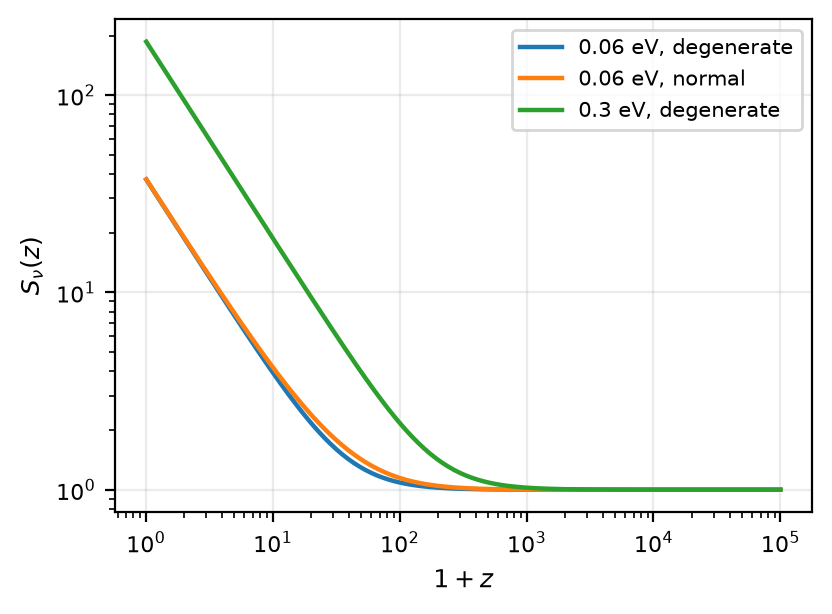

In [4]:
z = np.logspace(-2, 5, 300)
fig, ax = plt.subplots(figsize=(4.5, 3.2))
for sum_mnu, ordering in ((0.06, "degenerate"), (0.06, "normal"), (0.3, "degenerate")):
    cc = PLANCK18.replace(sum_mnu=sum_mnu, nu_hierarchy=ordering)
    ax.loglog(1 + z, nu_density_shape(z, cc), label=f"{sum_mnu} eV, {ordering}")
ax.set(xlabel="$1+z$", ylabel=r"$S_\nu(z)$")
ax.legend();

## Expansion and distances

The expansion rate with the complete budget reads (Eq. 12):

$$E^2(z) = \Omega_\gamma(1+z)^4 + \Omega_{\rm cb}(1+z)^3 + \big[(\Omega_\nu^{\rm ur}-\Omega_{\rm ur})S_\nu(z) + \Omega_{\rm ur}\big](1+z)^4 + \Omega_k(1+z)^2 + \Omega_{\rm DE}f_{\rm DE}(z),$$

with $f_{\rm DE}(z) = (1+z)^{3(1+w_0+w_a)}\exp[-3w_a z/(1+z)]$ for $w(a) = w_0 + w_a(1-a)$.
The comoving distance is its quadrature, in $h^{-1}$Mpc (Eq. 15),

$$\chi(z) = 2997.92458\int_0^z \frac{{\rm d}z'}{E(z')},$$

evaluated on 256 Gauss–Legendre nodes.
Curvature enters only through the transverse distance $f_K(\chi) = \chi\,s(x)$, $x = \Omega_k(\chi/D_H)^2$, $s(x) = \sinh\sqrt{x}/\sqrt{x}$ (Eq. 16).
$s$ is an entire function, so the flat case is an interior point and $f_K = \chi$ exactly at $\Omega_k = 0$.
The other distances follow from $f_K$ (Eq. 17).

flat: f_K == chi to the last bit: True


chi(z=1) = 2291.920 Mpc/h,  mu(z=1) = 44.1641 mag


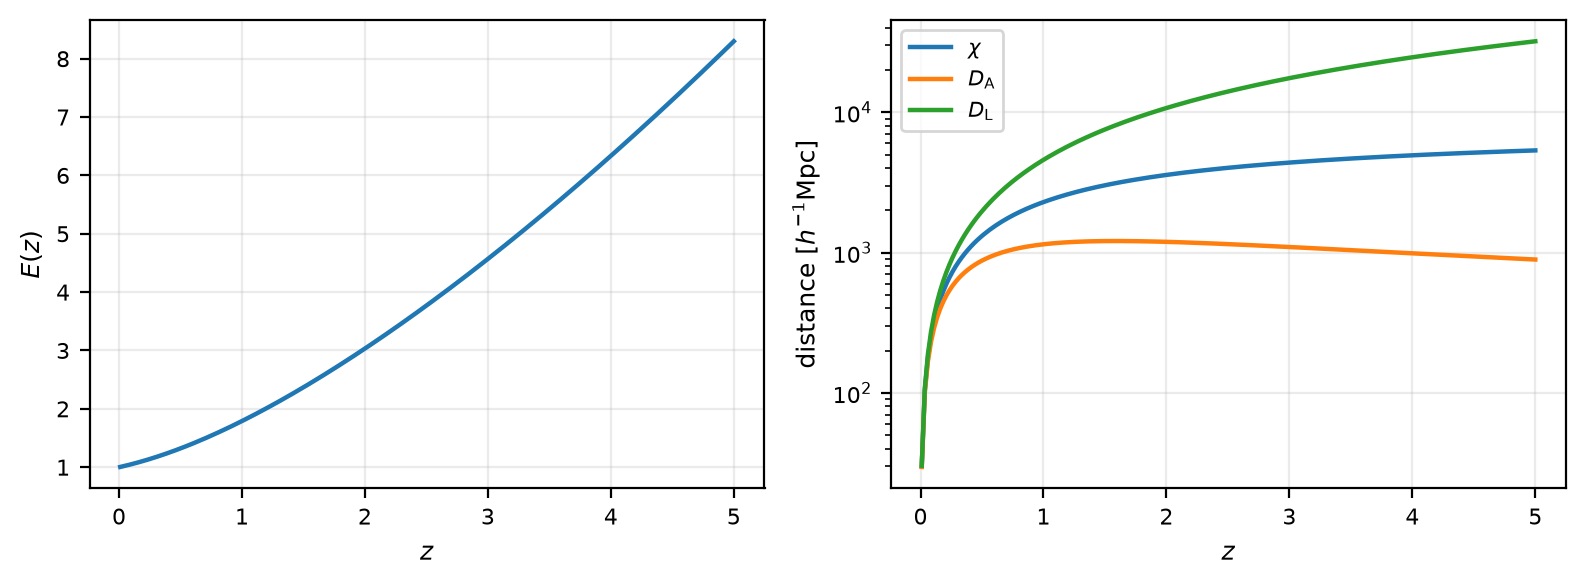

In [5]:
z = np.linspace(0.01, 5.0, 200)
fig, (a0, a1) = plt.subplots(1, 2, figsize=(8.0, 3.0))
a0.plot(z, hubble_e(z, PLANCK18))
a0.set(xlabel="$z$", ylabel="$E(z)$")
for f, label in ((comoving_distance, r"$\chi$"), (angular_diameter_distance, r"$D_{\rm A}$"),
                 (luminosity_distance, r"$D_{\rm L}$")):
    a1.semilogy(z, f(z, PLANCK18), label=label)
a1.set(xlabel="$z$", ylabel=r"distance [$h^{-1}$Mpc]")
a1.legend()
fig.tight_layout()

chi = comoving_distance(z, PLANCK18)
print("flat: f_K == chi to the last bit:", bool(np.all(transverse_distance(chi, PLANCK18) == chi)))
print(f"chi(z=1) = {float(comoving_distance(1.0, PLANCK18)[0]):.3f} Mpc/h,  "
      f"mu(z=1) = {float(distance_modulus(1.0, PLANCK18)[0]):.4f} mag")

### Exercise: the quadrature

Integrate $1/E$ yourself with `scipy.integrate.quad` at $z = 1$ and $z = 1100$ and compare with `comoving_distance`.

In [6]:
from scipy.integrate import quad

for zz in (1.0, 10.0, 1100.0):
    ref = 2997.92458 * quad(lambda x: 1.0 / float(hubble_e(x, PLANCK18)), 0.0, zz,
                            epsabs=0, epsrel=1e-13, limit=500)[0]
    print(f"z = {zz:6g}: chi / quad - 1 = {float(comoving_distance(zz, PLANCK18)[0]) / ref - 1:+.1e}")

z =      1: chi / quad - 1 = +0.0e+00
z =     10: chi / quad - 1 = +1.1e-15
z =   1100: chi / quad - 1 = -4.8e-13


## The sound horizon

The BAO scale is the comoving sound horizon at the drag epoch, $r_{\rm d} = \int_{z_{\rm d}}^\infty c_s\,{\rm d}z/H$ (Eq. 41), integrated over the same $E(z)$ as every distance here.
The drag redshift needs a recombination history, which this package does not carry; it is a cubic polynomial fitted to CLASS 3.3.4 with HyRec-2 on 1915 cosmologies across the `emu_pk` box, accurate to 0.017 in $z_{\rm d}$.
Outside that box the fit refuses; `in_domain(cosmo)` returns the box as a boolean for a sampler's prior.

In [7]:
from ggah_mod.cosmology.domain import in_domain

print(f"z_d = {float(z_drag(PLANCK18)):.3f},  r_d = {float(r_drag(PLANCK18)):.4f} Mpc/h "
      f"= {float(r_drag(PLANCK18)) / PLANCK18.h:.3f} Mpc")
print("PLANCK18 in the calibrated box:", bool(in_domain(PLANCK18)))

z_d = 1059.887,  r_d = 99.0861 Mpc/h = 147.099 Mpc


PLANCK18 in the calibrated box: True


## Derivatives

The derivatives of $\ln E$ are known in closed form (Eq. 21).
For instance, substituting the closure into $E^2$ gives

$$\frac{\partial\ln E}{\partial\ln\Omega_{\rm m}} = \frac{\Omega_{\rm m}(x^3-f)}{2E^2},\qquad
\frac{\partial\ln E}{\partial w_0} = \frac{3\,\Omega_{\rm DE} f\ln x}{2E^2},$$

with $x = 1+z$ and $f = f_{\rm DE}(z)$.
`ggah_mod` does not use these formulas: `jax.jacfwd` differentiates the code of $E(z)$ itself.
We check that the two agree.

In [8]:
z = jnp.linspace(0.1, 3.0, 30)


def lnE(value, name):
    return jnp.log(hubble_e(z, PLANCK18.replace(**{name: value})))


c = PLANCK18
x, E2 = 1 + z, hubble_e(z, c) ** 2
f = x ** (3 * (1 + c.w0 + c.wa)) * jnp.exp(-3 * c.wa * z / x)

auto_om = jax.jacfwd(lnE)(c.Omega_m, "Omega_m") * c.Omega_m      # logarithmic derivative
auto_w0 = jax.jacfwd(lnE)(c.w0, "w0")
closed_om = c.Omega_m * (x ** 3 - f) / (2 * E2)
closed_w0 = 3 * c.Omega_de * f * jnp.log(x) / (2 * E2)
print(f"Omega_m: max |autodiff - closed form| = {float(jnp.max(jnp.abs(auto_om - closed_om))):.1e}")
print(f"w0     : max |autodiff - closed form| = {float(jnp.max(jnp.abs(auto_w0 - closed_w0))):.1e}")

Omega_m: max |autodiff - closed form| = 1.1e-16
w0     : max |autodiff - closed form| = 2.8e-17


The distance's derivative is the integral of the one of $E$, with a minus sign (Eq. 22), so every direction the background sees moves $E$ and $\chi$ with opposite signs.

We now differentiate $\ln E$ and $\ln\chi$ with respect to all ten parameters.
A positive scale ($\Omega_{\rm m}$, $\Omega_{\rm b}$, $h$, $\sum m_\nu$, $T_{\rm CMB}$) gets a logarithmic derivative; a location, or a parameter that is already a logarithm, gets an absolute one.
One `jax.jacfwd` per parameter is cheaper than a reverse pass, because the output is a whole redshift grid and the input a scalar.

In [9]:
z = np.geomspace(0.01, 5.0, 240)
zj = jnp.asarray(z)
ge, gc = {}, {}
for p in T.DPARAMS:
    v0 = float(getattr(PLANCK18, p))
    scale = v0 if p in T.DLOG else 1.0
    ge[p] = np.asarray(jax.jacfwd(lambda v: jnp.log(hubble_e(zj, PLANCK18.replace(**{p: v}))))(v0)) * scale
    gc[p] = np.asarray(jax.jacfwd(lambda v: jnp.log(comoving_distance(zj, PLANCK18.replace(**{p: v}))))(v0)) * scale

print(f"{'':10s}{'dlnE at z=1':>14s}{'dlnchi at z=1':>15s}")
for p in T.DPARAMS:
    print(f"{p:10s}{np.interp(1.0, z, ge[p]):+14.4g}{np.interp(1.0, z, gc[p]):+15.4g}")

             dlnE at z=1  dlnchi at z=1
Omega_m           +0.344        -0.1822
Omega_b               +0             +0
h             -0.0002614     +0.0001163
sum_mnu       -3.118e-06     +1.179e-06
T_cmb         +0.0005258     -0.0002338
n_s                   +0             +0
ln10A_s               +0             +0
w0               +0.2219        -0.1888
wa              +0.06183       -0.03355
Omega_k          +0.4676        -0.2928


## The figure

Fig. 2 of the paper draws these twenty curves.
The vertical axis is `symlog`: linear inside the shaded band, where the derivative is below $10^{-7}$ in magnitude, and logarithmic outside it, because the curves span eight decades.

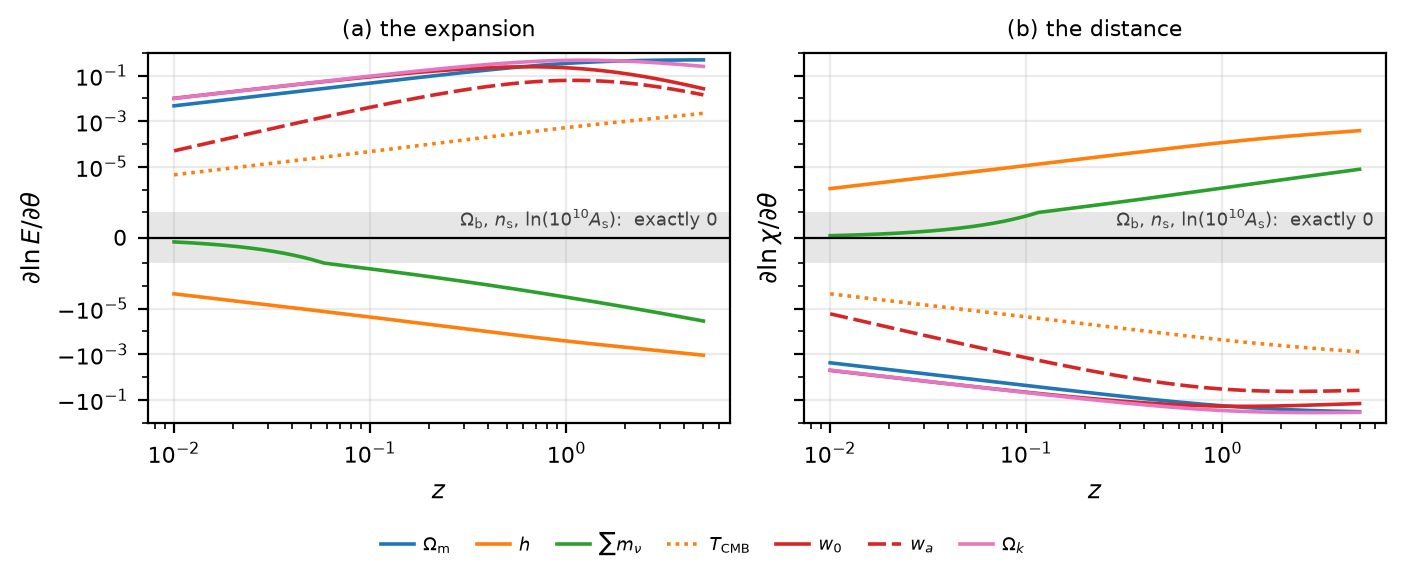

In [10]:
LIN = 1e-7
fig, ax = plt.subplots(1, 2, figsize=(7.1, 2.9), sharey=True)
for axis, g, sym, title in ((ax[0], ge, "E", "(a) the expansion"),
                            (ax[1], gc, r"\chi", "(b) the distance")):
    axis.axhspan(-LIN, LIN, color="0.90", zorder=0, lw=0)
    exact = [p for p in T.DPARAMS if np.all(g[p] == 0.0)]
    for p in T.DPARAMS:
        if p not in exact:
            colour, ls = T.DSTYLE[p]
            axis.plot(z, g[p], color=colour, ls=ls, lw=1.3, label=T.TEX[p])
    axis.set_xscale("log")
    axis.set_yscale("symlog", linthresh=LIN)
    axis.axhline(0.0, color="k", lw=0.8)
    axis.annotate(", ".join(T.TEX[p] for p in exact) + ":  exactly $0$",
                  xy=(0.98, 0.0), xycoords=("axes fraction", "data"), xytext=(0, 2.5),
                  textcoords="offset points", ha="right", va="bottom", fontsize=6.6, color="0.25")
    axis.set_ylim(-1.0, 1.0)
    axis.set_yticks([-1e-1, -1e-3, -1e-5, 0.0, 1e-5, 1e-3, 1e-1])
    axis.set(xlabel="$z$", title=title, ylabel=rf"$\partial\ln {sym}/\partial\theta$")
handles, labels = ax[1].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=6.6, ncol=len(labels), loc="lower center",
           bbox_to_anchor=(0.5, 0.0), frameon=False, handlelength=1.8, columnspacing=1.4, handletextpad=0.5)
fig.tight_layout(rect=(0.0, 0.07, 1.0, 1.0))
T.save_figure(fig, "fig_distance_gradients")

## Exercises

1. Redo the figure at $\Omega_k = 0.05$. Which curves change, and why does the $\Omega_k$ derivative of $\chi$ grow faster with redshift than that of $E$?
2. Swap `nu_hierarchy` to `"normal"` and plot the ratio of the $\sum m_\nu$ derivatives of $E$ in the two orderings. Where does the splitting matter?
3. Differentiate $r_{\rm d}$ with respect to $\Omega_{\rm b}$, $h$ and $\Omega_{\rm m}$ with `jax.grad`. Which combination of them does the BAO ratio $\chi(z)/r_{\rm d}$ constrain? (Notebook 07 answers it with a Fisher matrix.)

Next: notebook 02, the linear power spectrum.